# Project 1, Part 3: Regularization and Transfer to Data B

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/project_1
!ls data

Mounted at /content/drive
/content/drive/MyDrive/project_1
dataset_a_test.csv   dataset_b_test.csv  dataset_c_train.csv
dataset_a_train.csv  dataset_c_test.csv


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

DEVICE: cuda


In [3]:
SOURCE_A_TRAIN = pd.read_csv("./data/dataset_a_train.csv")
SOURCE_A_TEST = pd.read_csv("./data/dataset_a_test.csv")
SOURCE_B_TEST = pd.read_csv("./data/dataset_b_test.csv")
print(SOURCE_A_TRAIN.shape, SOURCE_A_TEST.shape, SOURCE_B_TEST.shape)

LABELS = pd.DataFrame({
    "Label": range(1, 6),
    "Set A": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
}).set_index("Label")

(7500, 3) (2500, 3) (2225, 3)


In [4]:
import copy
import json
import os

import joblib
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

SEED = 0              # same seed as Part 2
CLASS_IDS = [1, 2, 3, 4, 5]
NUM_CLASSES = len(CLASS_IDS)
MAX_EPOCHS = 30       # upper limit during the validation sweep
PATIENCE = 5          # early stopping patience (epochs without val macro-F1 gain)
P3_BATCH_SIZE = 64

os.makedirs("results/part3", exist_ok=True)
os.makedirs("models", exist_ok=True)


def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def article_text(df):
    # title + description, same as concat_article but safe for missing values
    return (df["Title"].fillna("").astype(str) + " " + df["Description"].fillna("").astype(str))

In [5]:
class RegMLP(nn.Module):
    """Same architecture as the Part 2 CustomMLP (input -> 128 -> 64 -> 5, ReLU),
    with the dropout rates exposed so Part 3 can vary them."""
    def __init__(self, input_dim, output_dim, dropout=(0.2, 0.3)):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(dropout[0]),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout[1]),
            nn.Linear(64, output_dim),
        )

    def forward(self, x):
        return self.layers(x)


def build_model(kind, input_dim, dropout=(0.0, 0.0)):
    if kind == "lr":
        return nn.Linear(input_dim, NUM_CLASSES)  # multinomial logistic regression
    return RegMLP(input_dim, NUM_CLASSES, dropout)

In [6]:
def batches(X, y=None, batch_size=P3_BATCH_SIZE, shuffle=False, rng=None):
    """Densify one batch at a time so the full TF-IDF matrix never sits on the GPU."""
    idx = np.arange(X.shape[0])
    if shuffle:
        rng.shuffle(idx)
    for start in range(0, len(idx), batch_size):
        b = idx[start:start + batch_size]
        xb = torch.tensor(X[b].toarray(), dtype=torch.float32, device=DEVICE)
        if y is None:
            yield xb
        else:
            yield xb, torch.tensor(y[b], dtype=torch.long, device=DEVICE)


def predict(model, X):
    model.eval()
    preds = []
    with torch.inference_mode():
        for xb in batches(X):
            preds.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(preds) + 1  # back to labels 1-5


def evaluate(y_true, y_pred, labels=CLASS_IDS):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "per_class": classification_report(y_true, y_pred, labels=labels,
                                           output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }


def train_model(kind, setting, X_train, y_train, X_val=None, y_val=None,
                epochs=MAX_EPOCHS, seed=SEED):
    """Train one model. y values are the original labels 1-5.
    With validation data: early stopping on validation macro-F1, keeps the best epoch.
    Without validation data: trains for exactly `epochs` epochs (used for the refit)."""
    set_seed(seed)
    rng = np.random.default_rng(seed)
    model = build_model(kind, X_train.shape[1], setting.get("dropout", (0.0, 0.0))).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=setting["lr"],
                           weight_decay=setting["weight_decay"])
    criterion = nn.CrossEntropyLoss()
    y_train0 = np.asarray(y_train) - 1  # CrossEntropyLoss wants 0-indexed labels

    best_f1, best_epoch, best_state, bad = -1.0, 0, None, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in batches(X_train, y_train0, shuffle=True, rng=rng):
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb)
        row = {"epoch": epoch, "train_loss": total / X_train.shape[0]}

        if X_val is not None:
            row["val_macro_f1"] = evaluate(y_val, predict(model, X_val))["macro_f1"]
            history.append(row)
            if row["val_macro_f1"] > best_f1:
                best_f1, best_epoch, bad = row["val_macro_f1"], epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
        else:
            history.append(row)

    if X_val is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = epochs
    return model, best_epoch, history

### Regularization settings
Logistic regression: L2 penalty through `weight_decay`. MLP: dropout and L2 `weight_decay`, from none to strong. Both use Adam and early stopping on Data A validation macro-F1.

In [7]:
LR_SETTINGS = {
    "lr_wd0":    {"lr": 1e-2, "weight_decay": 0.0},
    "lr_wd1e-5": {"lr": 1e-2, "weight_decay": 1e-5},
    "lr_wd1e-4": {"lr": 1e-2, "weight_decay": 1e-4},
    "lr_wd1e-3": {"lr": 1e-2, "weight_decay": 1e-3},
}

MLP_SETTINGS = {
    "mlp_none":       {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.0, 0.0)},
    "mlp_dropout":    {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.2, 0.3)},
    "mlp_dropout_wd": {"lr": 1e-3, "weight_decay": 1e-4, "dropout": (0.2, 0.3)},
    "mlp_strong":     {"lr": 1e-3, "weight_decay": 1e-3, "dropout": (0.5, 0.5)},
}

ALL_SETTINGS = {**{k: ("lr", v) for k, v in LR_SETTINGS.items()},
                **{k: ("mlp", v) for k, v in MLP_SETTINGS.items()}}

### Step 1: Sweep on the Data A validation split

In [8]:
# Same stratified 80/20 split as Part 2 (same random_state)
p3_train, p3_val = train_test_split(SOURCE_A_TRAIN, test_size=0.2,
                                    random_state=SEED, stratify=SOURCE_A_TRAIN["Label"])

p3_vec = TfidfVectorizer()  # raw unigram, fit on the 80% training split only
X_tr = p3_vec.fit_transform(article_text(p3_train))
X_val = p3_vec.transform(article_text(p3_val))
y_tr = p3_train["Label"].to_numpy()
y_val = p3_val["Label"].to_numpy()
print("train:", X_tr.shape, " val:", X_val.shape)

sweep_rows, best_epochs, histories = [], {}, {}
for name, (kind, setting) in ALL_SETTINGS.items():
    model, best_epoch, hist = train_model(kind, setting, X_tr, y_tr, X_val, y_val)
    m = evaluate(y_val, predict(model, X_val))
    best_epochs[name], histories[name] = best_epoch, hist
    sweep_rows.append({
        "setting": name, "model": kind.upper(), "lr": setting["lr"],
        "weight_decay": setting["weight_decay"], "dropout": str(setting.get("dropout", "n/a")),
        "best_epoch": best_epoch, "val_accuracy": m["accuracy"], "val_macro_f1": m["macro_f1"],
    })
    print(f"{name:16s} best_epoch={best_epoch:2d}  val acc={m['accuracy']:.4f}  val macro-F1={m['macro_f1']:.4f}")

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv("results/part3/validation_sweep.csv", index=False)
display(sweep_df)

train: (6000, 17857)  val: (1500, 17857)
lr_wd0           best_epoch= 4  val acc=0.8100  val macro-F1=0.8100
lr_wd1e-5        best_epoch= 6  val acc=0.8100  val macro-F1=0.8103
lr_wd1e-4        best_epoch= 5  val acc=0.8053  val macro-F1=0.8060
lr_wd1e-3        best_epoch= 1  val acc=0.7853  val macro-F1=0.7857
mlp_none         best_epoch= 2  val acc=0.8020  val macro-F1=0.8025
mlp_dropout      best_epoch= 2  val acc=0.8040  val macro-F1=0.8045
mlp_dropout_wd   best_epoch= 2  val acc=0.7973  val macro-F1=0.7979
mlp_strong       best_epoch= 9  val acc=0.7920  val macro-F1=0.7923


,setting,model,lr,weight_decay,dropout,best_epoch,val_accuracy,val_macro_f1
0,lr_wd0,LR,0.010,0.00000,n/a,4,0.810000,0.810021
1,lr_wd1e-5,LR,0.010,0.00001,n/a,6,0.810000,0.810313
2,lr_wd1e-4,LR,0.010,0.00010,n/a,5,0.805333,0.806006
3,lr_wd1e-3,LR,0.010,0.00100,n/a,1,0.785333,0.785671
4,mlp_none,MLP,0.001,0.00000,"(0.0, 0.0)",2,0.802000,0.802496
5,mlp_dropout,MLP,0.001,0.00000,"(0.2, 0.3)",2,0.804000,0.804527
6,mlp_dropout_wd,MLP,0.001,0.00010,"(0.2, 0.3)",2,0.797333,0.797937
7,mlp_strong,MLP,0.001,0.00100,"(0.5, 0.5)",9,0.792000,0.792338


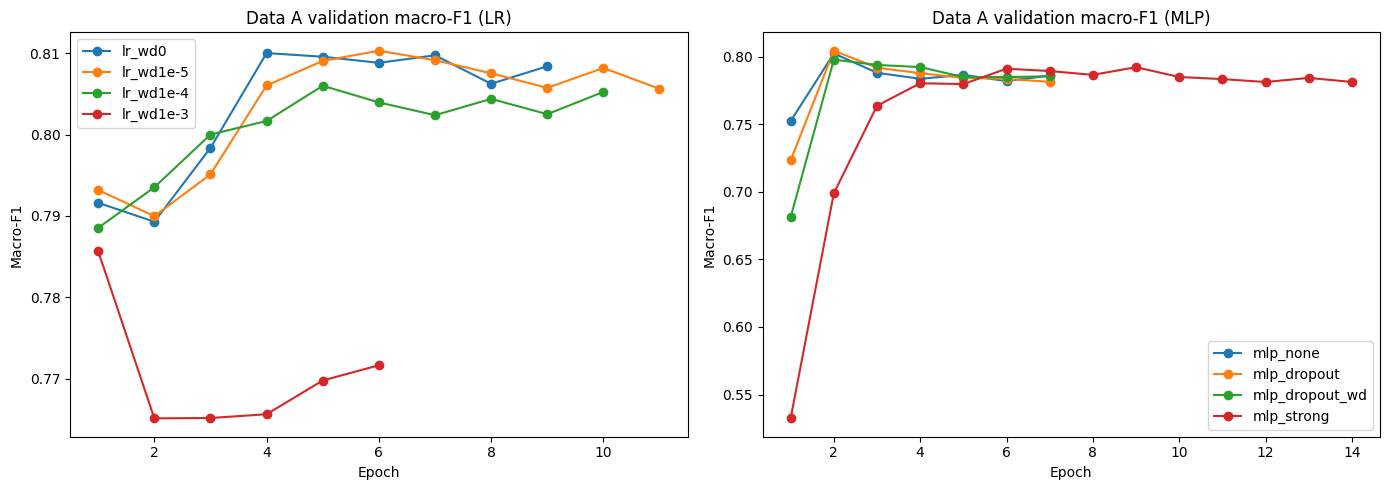

In [9]:
# Validation macro-F1 per epoch for every setting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, kind in zip(axes, ["lr", "mlp"]):
    for name, (k, _) in ALL_SETTINGS.items():
        if k == kind:
            h = pd.DataFrame(histories[name])
            ax.plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
    ax.set_title(f"Data A validation macro-F1 ({kind.upper()})")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()
plt.tight_layout()
plt.savefig("results/part3/validation_curves.png", dpi=150)
plt.show()

### Step 2: Select one setting per model (validation only)
The selection is saved before any test set is touched.

In [10]:
best_lr = sweep_df[sweep_df.model == "LR"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]
best_mlp = sweep_df[sweep_df.model == "MLP"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]

selection = {
    "seed": SEED,
    "criterion": "highest Data A validation macro-F1",
    "selected_lr": best_lr, "lr_config": ALL_SETTINGS[best_lr][1], "lr_epochs": best_epochs[best_lr],
    "selected_mlp": best_mlp, "mlp_config": ALL_SETTINGS[best_mlp][1], "mlp_epochs": best_epochs[best_mlp],
}
with open("results/part3/selection.json", "w") as f:
    json.dump(selection, f, indent=2)
print(json.dumps(selection, indent=2))

{
  "seed": 0,
  "criterion": "highest Data A validation macro-F1",
  "selected_lr": "lr_wd1e-5",
  "lr_config": {
    "lr": 0.01,
    "weight_decay": 1e-05
  },
  "lr_epochs": 6,
  "selected_mlp": "mlp_dropout",
  "mlp_config": {
    "lr": 0.001,
    "weight_decay": 0.0,
    "dropout": [
      0.2,
      0.3
    ]
  },
  "mlp_epochs": 2
}


### Step 3: Refit on all of Data A train, evaluate on Data A test and Data B test
The refit trains for the best epoch count found on validation, since there is no validation set left to early-stop on.

In [11]:
vec_full = TfidfVectorizer()  # refit on ALL of dataset_a_train.csv
X_a_full = vec_full.fit_transform(article_text(SOURCE_A_TRAIN))
y_a_full = SOURCE_A_TRAIN["Label"].to_numpy()
X_a_test = vec_full.transform(article_text(SOURCE_A_TEST))
y_a_test = SOURCE_A_TEST["Label"].to_numpy()
X_b_test = vec_full.transform(article_text(SOURCE_B_TEST))  # transform only, never fit
y_b_test = SOURCE_B_TEST["Label"].to_numpy()
print("vocab size:", len(vec_full.vocabulary_))

FINAL_MODELS, final_results = {}, {}
for tag, name in [("lr", best_lr), ("mlp", best_mlp)]:
    kind, setting = ALL_SETTINGS[name]
    model, _, _ = train_model(kind, setting, X_a_full, y_a_full, epochs=best_epochs[name])
    FINAL_MODELS[tag] = model
    torch.save(model.state_dict(), f"models/part3_final_{tag}.pt")
    final_results[tag] = {
        "setting": name, "config": setting, "epochs": best_epochs[name], "seed": SEED,
        "representation": "unigram TF-IDF, title + description",
        "train_data": "all of dataset_a_train.csv", "train_size": len(SOURCE_A_TRAIN),
        "A_test": evaluate(y_a_test, predict(model, X_a_test)),
        "B_test": evaluate(y_b_test, predict(model, X_b_test)),
    }
joblib.dump(vec_full, "models/part3_vectorizer.joblib")

with open("results/part3/final_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

summary = pd.DataFrame([{
    "model": tag.upper(), "setting": r["setting"],
    "A_test_acc": r["A_test"]["accuracy"], "A_test_macro_f1": r["A_test"]["macro_f1"],
    "B_test_acc": r["B_test"]["accuracy"], "B_test_macro_f1": r["B_test"]["macro_f1"],
} for tag, r in final_results.items()])
display(summary)

vocab size: 19834


,model,setting,A_test_acc,A_test_macro_f1,B_test_acc,B_test_macro_f1
0,LR,lr_wd1e-5,0.5648,0.564727,0.780225,0.788776
1,MLP,mlp_dropout,0.5784,0.574852,0.792360,0.794088


,model,label,class,A_precision,A_recall,A_f1,B_precision,B_recall,B_f1,f1_drop
0,LR,1,Politics,0.383,0.374,0.379,0.938,0.542,0.687,-0.308
1,LR,2,Sports,0.652,0.664,0.658,0.982,0.871,0.923,-0.265
2,LR,3,Business,0.612,0.564,0.587,0.527,0.990,0.688,-0.101
3,LR,4,Technology,0.683,0.684,0.683,0.981,0.643,0.777,-0.094
4,LR,5,Entertainment,0.497,0.538,0.517,0.977,0.782,0.869,-0.352
5,MLP,1,Politics,0.404,0.372,0.388,0.874,0.468,0.609,-0.222
6,MLP,2,Sports,0.667,0.696,0.681,0.983,0.896,0.938,-0.257
7,MLP,3,Business,0.612,0.552,0.580,0.556,0.986,0.711,-0.131
8,MLP,4,Technology,0.662,0.748,0.702,0.931,0.746,0.828,-0.126
9,MLP,5,Entertainment,0.522,0.524,0.523,0.990,0.798,0.884,-0.361


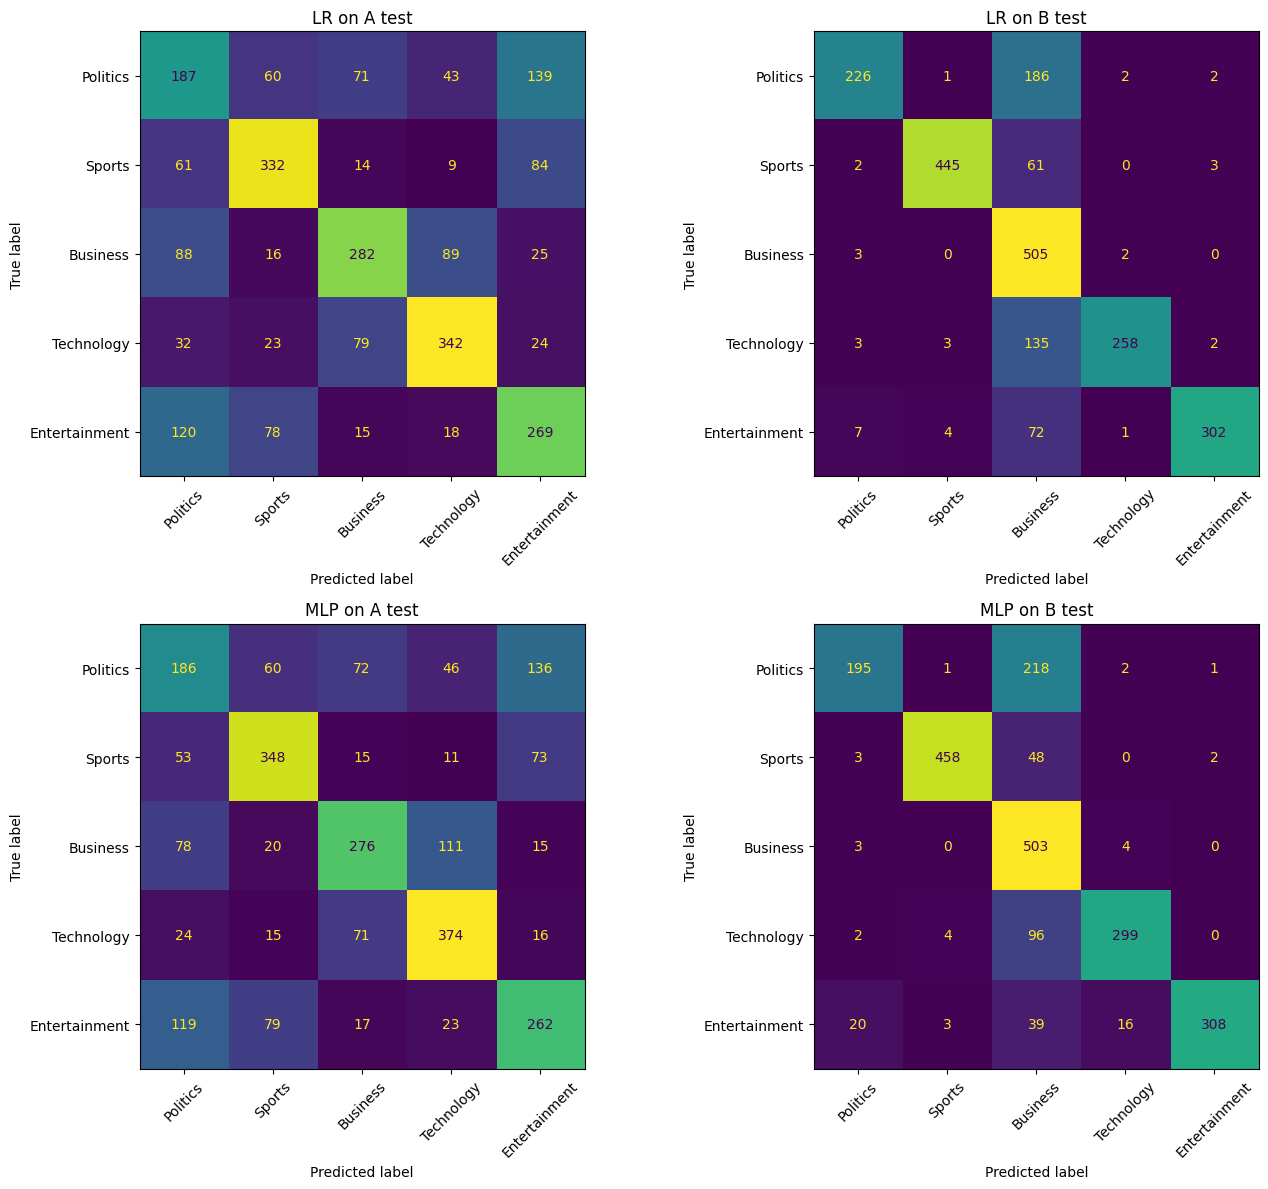

In [12]:
# Per-class precision / recall / F1, Data A vs Data B
rows = []
for tag, r in final_results.items():
    for lab in CLASS_IDS:
        a, b = r["A_test"]["per_class"][str(lab)], r["B_test"]["per_class"][str(lab)]
        rows.append({"model": tag.upper(), "label": lab, "class": LABELS.loc[lab, "Set A"],
                     "A_precision": a["precision"], "A_recall": a["recall"], "A_f1": a["f1-score"],
                     "B_precision": b["precision"], "B_recall": b["recall"], "B_f1": b["f1-score"],
                     "f1_drop": a["f1-score"] - b["f1-score"]})
per_class = pd.DataFrame(rows)
per_class.to_csv("results/part3/per_class_A_vs_B.csv", index=False)
display(per_class.round(3))

# Confusion matrices
class_names = list(LABELS["Set A"])
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for i, tag in enumerate(["lr", "mlp"]):
    for j, ds in enumerate(["A_test", "B_test"]):
        cm = np.array(final_results[tag][ds]["confusion_matrix"])
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=axes[i, j], colorbar=False, xticks_rotation=45)
        axes[i, j].set_title(f"{tag.upper()} on {ds.replace('_', ' ')}")
plt.tight_layout()
plt.savefig("results/part3/confusion_matrices.png", dpi=150)
plt.show()

### Step 4 (post hoc): every setting on the test sets
Reported for analysis only. These numbers were not used to pick the final models.

In [13]:
posthoc = []
for name, (kind, setting) in ALL_SETTINGS.items():
    model, _, _ = train_model(kind, setting, X_a_full, y_a_full, epochs=best_epochs[name])
    fa = evaluate(y_a_test, predict(model, X_a_test))["macro_f1"]
    fb = evaluate(y_b_test, predict(model, X_b_test))["macro_f1"]
    posthoc.append({"setting": name, "model": kind.upper(),
                    "A_test_macro_f1": fa, "B_test_macro_f1": fb, "A_minus_B": fa - fb})
posthoc_df = pd.DataFrame(posthoc)
posthoc_df.to_csv("results/part3/posthoc_all_settings.csv", index=False)
display(posthoc_df.round(4))

,setting,model,A_test_macro_f1,B_test_macro_f1,A_minus_B
0,lr_wd0,LR,0.5599,0.7864,-0.2266
1,lr_wd1e-5,LR,0.5647,0.7888,-0.2240
2,lr_wd1e-4,LR,0.5626,0.7597,-0.1971
3,lr_wd1e-3,LR,0.5472,0.5494,-0.0021
4,mlp_none,MLP,0.5749,0.8230,-0.2482
5,mlp_dropout,MLP,0.5749,0.7941,-0.2192
6,mlp_dropout_wd,MLP,0.5723,0.7797,-0.2075
7,mlp_strong,MLP,0.5519,0.7357,-0.1838


### Step 5: Transfer diagnostics (for the A vs B discussion)
Class balance, text length in words, and out-of-vocabulary rate relative to the Data A vocabulary.

In [14]:
def word_count(s):
    return s.fillna("").astype(str).str.split().str.len()

analyzer, vocab = vec_full.build_analyzer(), vec_full.vocabulary_
diag_rows = []
for dname, df in [("A_train", SOURCE_A_TRAIN), ("A_test", SOURCE_A_TEST), ("B_test", SOURCE_B_TEST)]:
    toks = [t for doc in article_text(df) for t in analyzer(doc)]
    props = df["Label"].value_counts(normalize=True).sort_index()
    diag_rows.append({
        "dataset": dname, "n": len(df),
        **{f"pct_label_{k}": round(100 * props.get(k, 0), 1) for k in CLASS_IDS},
        "title_words_median": word_count(df["Title"]).median(),
        "desc_words_median": word_count(df["Description"]).median(),
        "oov_rate_vs_A_vocab": round(float(np.mean([t not in vocab for t in toks])), 4),
    })
diag_df = pd.DataFrame(diag_rows)
diag_df.to_csv("results/part3/transfer_diagnostics.csv", index=False)
display(diag_df)

,dataset,n,pct_label_1,pct_label_2,pct_label_3,pct_label_4,pct_label_5,title_words_median,desc_words_median,oov_rate_vs_A_vocab
0,A_train,7500,20.0,20.0,20.0,20.0,20.0,10.0,17.0,0.0000
1,A_test,2500,20.0,20.0,20.0,20.0,20.0,11.0,15.0,0.0528
2,B_test,2225,18.7,23.0,22.9,18.0,17.3,5.0,326.0,0.0736


Checking whether duplicate articles explain the gap between validation and A test scores.

In [15]:
dup_rows = SOURCE_A_TRAIN.duplicated().sum()
dup_text = article_text(SOURCE_A_TRAIN).duplicated().sum()
train_text = set(article_text(p3_train))
val_overlap = article_text(p3_val).isin(train_text).sum()
test_overlap = article_text(SOURCE_A_TEST).isin(set(article_text(SOURCE_A_TRAIN))).sum()
print("duplicate rows in A train:", dup_rows)
print("duplicate texts in A train:", dup_text)
print("val articles also in train split:", val_overlap, "/", len(p3_val))
print("A test articles also in A train:", test_overlap, "/", len(SOURCE_A_TEST))

duplicate rows in A train: 47
duplicate texts in A train: 47
val articles also in train split: 15 / 1500
A test articles also in A train: 0 / 2500


### Frozen models for Part 4
`FINAL_MODELS["lr"]`, `FINAL_MODELS["mlp"]`, and `vec_full` stay in memory. They are also saved to `models/`. To reload them in a fresh session:

```python
vec_full = joblib.load("models/part3_vectorizer.joblib")
n_feat = len(vec_full.vocabulary_)
FINAL_MODELS = {}
for tag in ["lr", "mlp"]:
    kind, setting = ALL_SETTINGS[selection[f"selected_{tag}"]]
    m = build_model(kind, n_feat, setting.get("dropout", (0.0, 0.0))).to(DEVICE)
    m.load_state_dict(torch.load(f"models/part3_final_{tag}.pt", map_location=DEVICE))
    FINAL_MODELS[tag] = m.eval()
```